## Multiplicação de Matrizes Paralela
### Programação Paralela e Distribuída (2026/2) - UFSCar

**Integrantes**
- Enzo Dezem Alves - 801743
- Gustavo Cesar Bento Laurindo - 821402
- Gustavo de Oliveira Gimenes - 820759
- Tiago de Paula Evangelista - 824369

### Introdução

Este trabalho aplica os conhecimentos teóricos e práticos da disciplina no estudo e no desenvolvimento de uma aplicação paralela relevante. O problema escolhido é a **multiplicação de matrizes**, retirado do conjunto da Maratona de Programação Paralela (SBAC-PAD). É uma operação central em computação científica, aprendizado de máquina e simulações numéricas, e seu alto custo computacional ($O(n^3)$) a torna um bom caso para explorar diferentes modelos de paralelismo.

Partindo de uma versão sequencial de referência, o problema é modelado e decomposto em tarefas independentes, e então implementado em três plataformas:

- **Memória compartilhada**, com threads usando OpenMP;
- **Memória distribuída**, com passagem de mensagens usando MPI;
- **GPU**, explorando o paralelismo massivo de dados com CUDA.

Mais do que apenas paralelizar, o objetivo é justificar as decisões de projeto de cada versão, analisando o impacto da comunicação, da granularidade das tarefas e do balanceamento de carga no desempenho obtido. Ao final, as implementações são comparadas em uma análise de desempenho (tempo de execução, speedup e eficiência).

### Utilitários

Infraestrutura compartilhada por todas as implementações: a medição de tempo padronizada, usada na análise de desempenho, e as funções que geram os diagramas.

#### Execução e medição

No Colab, abra este arquivo e execute as células em ordem. Para executar CUDA, selecione **Ambiente de execução → Alterar tipo de ambiente de execução → GPU**. Em Linux ou WSL, use o ambiente Jupyter e os compiladores descritos no README. O notebook inclui os códigos e compila cópias em um diretório temporário.

Todos os programas recebem `n m p` para $A_{n\times m} B_{m\times p}$, ou apenas `n` para matrizes quadradas. O código usa `double`, armazenamento contíguo por linhas e entradas determinísticas. Cada execução emite `RESULT,implementação,n,m,p,workers,tempo_s,checksum`. O campo `workers` indica threads no OpenMP, ranks no MPI e blocos lançados em CUDA.

O tempo mede a obtenção de $C$ com $A$ e $B$ já inicializadas na memória do host (ou do rank 0). Inclui a região paralela OpenMP, as três coletivas MPI e as cópias CPU ↔ GPU. A criação de processos MPI, a alocação, a inicialização e a validação são executadas fora da região cronometrada. O tempo total com inicialização do processo é medido separadamente na seção de *hotspot*.

In [1]:
import os
from pathlib import Path
import shlex
import shutil
import statistics
import subprocess
import tempfile
from datetime import datetime, timezone

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

RUN_DIR = Path.cwd()
BUILD = Path(tempfile.mkdtemp(prefix="matmul-"))
SRC, BIN = BUILD / "src", BUILD / "bin"
SRC.mkdir()
BIN.mkdir()

SIZES = [int(n) for n in os.getenv("MATMUL_SIZES", "256 512 1024 2048").split()]
REPS = int(os.getenv("MATMUL_REPS", "5"))
CPUS = min(8, len(os.sched_getaffinity(0)))
THREADS = sorted({1, CPUS} | {t for t in (2, 4, 8) if t <= CPUS})
RESULTS = []
LOCAL_RUN = "local"
RUN_DATE = datetime.now(timezone.utc).isoformat(timespec="seconds")
CPU_MODEL = next(
    (line.partition(":")[2].strip() for line in Path("/proc/cpuinfo").read_text().splitlines()
     if line.startswith("model name")), "consulte lscpu"
)
GPU_INFO = ""

if Path("/content").is_dir() and not all(shutil.which(x) for x in ("mpicc", "mpirun")):
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(["apt-get", "install", "-y", "-qq", "openmpi-bin", "libopenmpi-dev"], check=True)

print(f"{RUN_DATE}\n{CPU_MODEL}\n{os.uname().release}\nThreads testadas: {THREADS}")
print(subprocess.check_output(["gcc", "--version"], text=True).splitlines()[0])


def write_source(name, text):
    (SRC / name).write_text(text, encoding="utf-8")
    print(f"Fonte preparada: {name}")


def compile_c(src, out, compiler="gcc", flags="-O3"):
    cmd = [compiler, *shlex.split(flags), str(SRC / src), "-o", str(BIN / out)]
    subprocess.run(cmd, check=True)
    print(shlex.join(cmd))


def parse_output(stdout):
    record, detail = None, None
    for line in stdout.splitlines():
        if line.startswith("RESULT,"):
            _, impl, n, m, p, workers, elapsed, check = line.split(",")
            if record is not None:
                raise ValueError("A execução emitiu mais de uma linha RESULT")
            record = dict(impl=impl, n=int(n), m=int(m), p=int(p), workers=int(workers),
                          time_s=float(elapsed), checksum=float(check), nodes=1)
        elif line.startswith("DETAIL,"):
            detail = line.split(",")[1:]
    if record is None or record["time_s"] <= 0:
        raise ValueError(f"RESULT ausente ou tempo inválido\n{stdout}")
    if record["impl"] == "mpi":
        _, nodes, scatter, bcast, compute, gather = detail
        record.update(nodes=int(nodes), scatter_s=float(scatter), bcast_s=float(bcast),
                      compute_max_s=float(compute), gather_s=float(gather))
    elif record["impl"] == "cuda":
        _, h2d, kernel, d2h = detail
        record.update(h2d_s=float(h2d), kernel_s=float(kernel), d2h_s=float(d2h))
    return record


def run_once(cmd, env=None):
    result = subprocess.run(shlex.split(cmd), capture_output=True, text=True, timeout=120,
                            env={**os.environ, "MATMUL_VERIFY": "0", **(env or {})})
    if result.returncode:
        raise RuntimeError(f"Falha em {cmd}\n{result.stdout}\n{result.stderr}")
    return parse_output(result.stdout)


def benchmark(cmd, reps=REPS, env=None, phase="principal"):
    runs = [run_once(cmd, env) for _ in range(reps)]
    for rep, record in enumerate(runs, start=1):
        RESULTS.append({**record, "rep": rep, "run": LOCAL_RUN, "phase": phase})
    times = [r["time_s"] for r in runs]
    mean = statistics.mean(times)
    std = statistics.stdev(times) if reps > 1 else 0.0
    r0 = runs[0]
    print(f"{r0['impl']:<19} n={r0['n']:>4} workers={r0['workers']:>4} | {mean:.6f} ± {std:.6f} s")
    return {**r0, "mean_s": mean, "std_s": std}


def results_table():
    df = pd.DataFrame(RESULTS).query("phase == 'principal'")
    return (df.groupby(["impl", "n", "m", "p", "workers"])
              .agg(mean_s=("time_s", "mean"), std_s=("time_s", "std"))
              .reset_index())

2026-11-17T19:57:04+00:00
Intel(R) Core(TM) i5-14600K
6.6.87.2-microsoft-standard-WSL2
Threads testadas: [1, 2, 4, 8]
gcc (Ubuntu 15.2.0-16ubuntu1) 15.2.0


In [2]:
write_source('common.h', r"""/* Infraestrutura comum a todas as implementações de multiplicação de matrizes.
 * Notação do enunciado: A (n x m) * B (m x p) = C (n x p), com c_ik = sum_j a_ij * b_jk. */
#ifndef COMMON_H
#define COMMON_H

#ifndef _POSIX_C_SOURCE
#define _POSIX_C_SOURCE 199309L
#endif
#include <errno.h>
#include <limits.h>
#include <math.h>
#include <stdint.h>
#include <stdio.h>
#include <stdlib.h>
#include <string.h>
#include <time.h>

typedef struct { int n, m, p; } dims_t;

/* Tempo de parede em segundos (relógio monotônico, imune a ajustes do relógio do sistema). */
static inline double wall_time(void) {
    struct timespec ts;
    clock_gettime(CLOCK_MONOTONIC, &ts);
    return ts.tv_sec + ts.tv_nsec * 1e-9;
}

static inline int positive_int(const char *text) {
    char *end;
    errno = 0;
    long value = strtol(text, &end, 10);
    return (errno || end == text || *end || value <= 0 || value > INT_MAX)
        ? 0 : (int)value;
}

/* Lê as dimensões: "prog n m p", ou "prog n" para matrizes quadradas (padrão: 1024). */
static inline dims_t parse_dims(int argc, char **argv) {
    dims_t d = {1024, 1024, 1024};
    if (argc == 4) {
        d.n = positive_int(argv[1]);
        d.m = positive_int(argv[2]);
        d.p = positive_int(argv[3]);
    } else if (argc != 1)
        d.n = d.m = d.p = (argc == 2) ? positive_int(argv[1]) : 0;
    if (d.n <= 0 || d.m <= 0 || d.p <= 0) {
        fprintf(stderr, "Uso: %s n [m p]  (dimensões positivas)\n", argv[0]);
        exit(EXIT_FAILURE);
    }
    return d;
}

/* Aloca uma matriz rows x cols contígua (row-major), opcionalmente zerada. */
static inline double *alloc_matrix(int rows, int cols, int zero) {
    if ((size_t)rows > SIZE_MAX / sizeof(double) / (size_t)cols) {
        fprintf(stderr, "Dimensões excedem o tamanho máximo de alocação\n");
        exit(EXIT_FAILURE);
    }
    size_t count = (size_t)rows * cols;
    if (count == 0) count = 1; /* Um buffer válido para ranks sem linhas. */
    double *M = (double *)(zero ? calloc(count, sizeof(double)) : malloc(count * sizeof(double)));
    if (!M) { fprintf(stderr, "Falha ao alocar %zu bytes\n", count * sizeof(double)); exit(EXIT_FAILURE); }
    return M;
}

/* Preenchimento determinístico: todas as versões multiplicam as mesmas matrizes.
 * a_ij para 0 <= i < n, 0 <= j < m;  b_jk para 0 <= j < m, 0 <= k < p. */
static inline void init_matrices(dims_t d, double *A, double *B) {
    for (int i = 0; i < d.n; i++)
        for (int j = 0; j < d.m; j++)
            A[(size_t)i * d.m + j] = (((size_t)i * 7 + (size_t)j * 3) % 11) / 10.0;
    for (int j = 0; j < d.m; j++)
        for (int k = 0; k < d.p; k++)
            B[(size_t)j * d.p + k] = (((size_t)j * 5 + (size_t)k * 2) % 13) / 10.0;
}

/* Ative em casos pequenos para conferir cada elemento por produto escalar. */
static inline int verify_matrix(dims_t d, const double *A, const double *B, const double *C) {
    const char *enabled = getenv("MATMUL_VERIFY");
    if (!enabled || strcmp(enabled, "1") != 0) return 1;

    for (int i = 0; i < d.n; i++)
        for (int k = 0; k < d.p; k++) {
            double expected = 0.0;
            for (int j = 0; j < d.m; j++)
                expected += A[(size_t)i * d.m + j] * B[(size_t)j * d.p + k];
            double actual = C[(size_t)i * d.p + k];
            if (!(fabs(actual - expected) <= 1e-12 + 1e-10 * fabs(expected))) {
                fprintf(stderr, "C[%d,%d] = %.17g, esperado %.17g\n", i, k, actual, expected);
                return 0;
            }
        }
    return 1;
}

/* Soma de todos os elementos de C (n x p), usada para validar as versões paralelas. */
static inline double checksum(dims_t d, const double *C) {
    double s = 0.0;
    for (size_t idx = 0; idx < (size_t)d.n * d.p; idx++) s += C[idx];
    return s;
}

/* Linha padronizada lida pela função benchmark() do notebook. */
static inline void report(const char *impl, dims_t d, int workers, double seconds, double chk) {
    printf("RESULT,%s,%d,%d,%d,%d,%.9f,%.17g\n", impl, d.n, d.m, d.p, workers, seconds, chk);
}

#endif
""")

Fonte preparada: common.h


#### Funções de desenho

Os diagramas são recriados a cada execução. Azul representa $A$, laranja representa $B$ e violeta representa $C$.

In [3]:
# Funções de desenho compartilhadas por todos os diagramas do notebook.
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

(BUILD / "figuras").mkdir(exist_ok=True)

# Cores fixas por papel: A = azul, B = laranja, C = violeta (paleta segura para daltonismo).
BLUE, ORANGE, VIOLET = "#2a78d6", "#eb6834", "#6250d6"
INK, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#c9c8c2", "#fcfcfb"
# Cores para identificar workers (threads, processos ou blocos), distintas das cores de A, B e C.
WORKER_COLORS = ["#1baf7a", "#eda100", "#e87ba4", "#008300"]

def draw_matrix(ax, x0, y0, rows, cols, title="", fills=None, cell=1.0):
    """Desenha uma grade rows x cols com canto superior esquerdo em (x0, y0).
    fills: {(linha, coluna): cor}. Retorna uma função que dá o centro da célula (r, c)."""
    fills = fills or {}
    for r in range(rows):
        for c in range(cols):
            ax.add_patch(Rectangle((x0 + c * cell, y0 - (r + 1) * cell), cell, cell,
                                   facecolor=fills.get((r, c), SURF), edgecolor=GRID, lw=1.2))
    ax.add_patch(Rectangle((x0, y0 - rows * cell), cols * cell, rows * cell,
                           fill=False, edgecolor=INK, lw=1.6))
    if title:
        ax.text(x0 + cols * cell / 2, y0 + 0.45, title, ha="center", va="bottom", fontsize=12, color=INK)
    return lambda r, c: (x0 + (c + .5) * cell, y0 - (r + .5) * cell)

def product_layout(ax, n, m, p, gap=1.6):
    """Posiciona A (n x m) × B (m x p) = C (n x p) lado a lado; retorna (xa, xb, xc, topo)."""
    xa, xb = 0, m + gap
    xc, top = xb + p + gap, max(n, m)
    ax.text(xa + m + gap / 2, top - n / 2, "×", ha="center", va="center", fontsize=22, color=INK)
    ax.text(xb + p + gap / 2, top - n / 2, "=", ha="center", va="center", fontsize=22, color=INK)
    return xa, xb, xc, top

def arrow(ax, start, end, color=INK):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=14, color=color, lw=2))

def h_arrow(ax, center_of, row, c0, c1):
    """Seta horizontal atravessando as células (row, c0)..(row, c1)."""
    (x0, y), (x1, _) = center_of(row, c0), center_of(row, c1)
    arrow(ax, (x0 - .3, y), (x1 + .3, y))

def label(ax, xy, text, fontsize=10):
    """Rótulo com fundo claro, legível sobre qualquer preenchimento."""
    ax.text(*xy, text, ha="center", va="center", fontsize=fontsize, color=INK,
            bbox=dict(boxstyle="round,pad=0.2", facecolor=SURF, edgecolor="none", alpha=0.9))

def finish(ax, width, top, bottom=-1.6):
    ax.set_xlim(-0.5, width + 0.5); ax.set_ylim(bottom, top + 1.2)
    ax.set_aspect("equal"); ax.axis("off")

def save_figure(fig, name):
    fig.savefig(BUILD / "figuras" / f"{name}.png", dpi=150, bbox_inches="tight", facecolor=SURF)
    plt.show()

### Implementação sequencial

#### O problema

O produto $C$ de duas matrizes $A$ e $B$ é definido como

$$c_{ik} = \sum_{j} a_{ij} \, b_{jk},$$

em que o índice $j$ é somado para cada par $(i, k)$. No enunciado isso aparece em notação de Einstein, com a soma implícita no índice repetido. Para o produto estar definido, o número de colunas de $A$ deve ser igual ao número de linhas de $B$:

$$(n \times m)\,(m \times p) = (n \times p),$$

ou seja, $A$ tem dimensão $n \times m$, $B$ tem $m \times p$ e $C$ tem $n \times p$, com $0 \le i < n$, $0 \le j < m$ e $0 \le k < p$.

Cada um dos $n \cdot p$ elementos de $C$ exige $m$ multiplicações e $m$ somas, ou seja, $2nmp$ operações de ponto flutuante no total, sobre $nm + mp + np$ valores de dados. Para matrizes quadradas ($n = m = p$) são $2n^3$ operações sobre $3n^2$ dados. Essa razão de $O(n)$ operações por dado faz do problema um caso **limitado por computação**, e não por memória, o que é favorável à paralelização. Além disso, os elementos de $C$ são **independentes entre si**: nenhum $c_{ik}$ depende de outro, o que será a base da decomposição nas próximas seções.

Convenções adotadas em todas as implementações:
- as implementações aceitam quaisquer dimensões $n$, $m$ e $p$. Na análise de desempenho usamos matrizes quadradas ($n = m = p$), que é o padrão para comparar escalabilidade, e os casos retangulares entram na validação;
- matrizes de `double` armazenadas em um **vetor contíguo em ordem por linhas** (*row-major*): o elemento $a_{ij}$ está em `A[i*m + j]`, $b_{jk}$ em `B[j*p + k]` e $c_{ik}$ em `C[i*p + k]`. Esse formato é necessário para enviar blocos com MPI e copiar dados para a GPU sem conversões;
- $A$ e $B$ são preenchidas por uma fórmula determinística, para que todas as versões multipliquem exatamente as mesmas matrizes;
- a correção é verificada por um *checksum* (soma de todos os elementos de $C$), comparado com o resultado da versão sequencial.

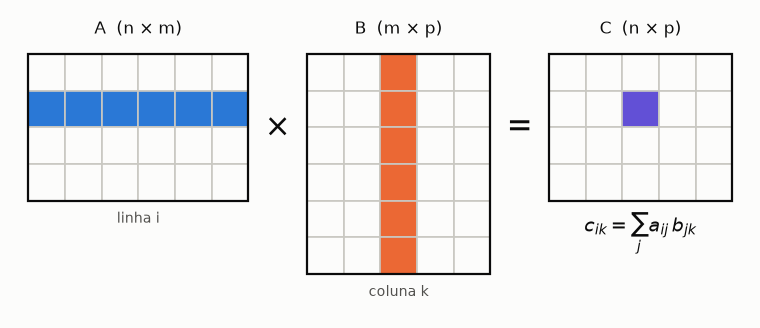

In [4]:
# Figura: definição do problema (linha i de A combinada com a coluna k de B gera c_ik)
n, m, p = 4, 6, 5
i, k = 1, 2

fig, ax = plt.subplots(figsize=(11, 4), facecolor=SURF)
xa, xb, xc, top = product_layout(ax, n, m, p)
draw_matrix(ax, xa, top, n, m, "A  (n × m)", {(i, c): BLUE for c in range(m)})
draw_matrix(ax, xb, top, m, p, "B  (m × p)", {(r, k): ORANGE for r in range(m)})
draw_matrix(ax, xc, top, n, p, "C  (n × p)", {(i, k): VIOLET})
ax.text(xa + m / 2, top - n - 0.3, "linha i", ha="center", va="top", color=MUTED, fontsize=10)
ax.text(xb + p / 2, top - m - 0.3, "coluna k", ha="center", va="top", color=MUTED, fontsize=10)
ax.text(xc + p / 2, top - n - 0.3, r"$c_{ik} = \sum_j a_{ij}\,b_{jk}$", ha="center", va="top",
        fontsize=14, color=INK)
finish(ax, xc + p, top, bottom=top - m - 1.2)
save_figure(fig, "problem")

#### Versão sequencial

A versão sequencial é a **referência** para o cálculo de *speedup* e a validação de todas as outras. Os índices dos laços seguem o enunciado: $i$ percorre as linhas de $C$, $k$ percorre as colunas de $C$ e $j$ é o índice somado.

A tradução direta da fórmula é a ordem **`i-k-j`**, que calcula cada $c_{ik}$ como um produto escalar completo:

```c
for i: for k: for j: C[i][k] += A[i][j] * B[j][k];
```

Nessa ordem, o laço interno percorre `B[j][k]` **por coluna**, com saltos de $p$ elementos na memória, o que gera uma falta de cache a cada acesso. Por isso usamos a ordem **`i-j-k`**:

```c
for i: for j: { a = A[i][j]; for k: C[i][k] += a * B[j][k]; }
```

O resultado é o mesmo, porque a soma em $j$ só muda de posição no aninhamento. Agora o laço interno percorre a linha `B[j][·]` e a linha `C[i][·]` **sequencialmente** (*stride* 1). Isso aproveita as linhas de cache inteiras e permite que o compilador vetorize o laço com instruções SIMD. O número de operações é o mesmo, mas o tempo é muito menor. Usar como referência uma versão sequencial já otimizada evita *speedups* inflados nas versões paralelas.

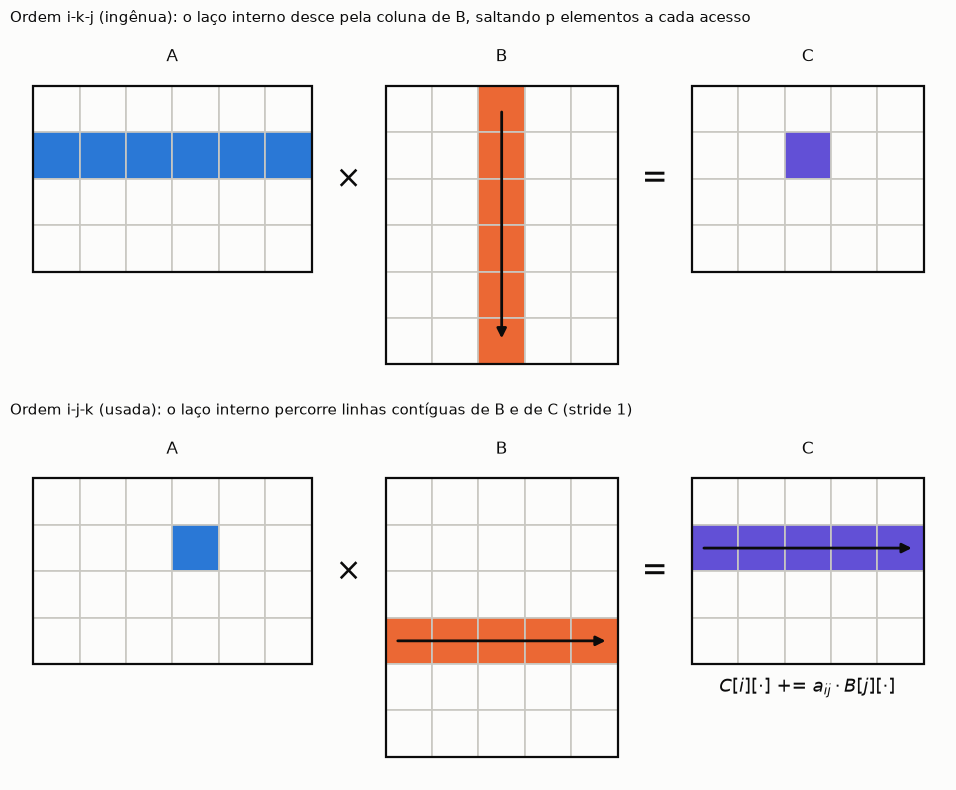

In [5]:
# Figura: padrão de acesso à memória das duas ordens de laço
n, m, p = 4, 6, 5
i, j, k = 1, 3, 2

fig, axes = plt.subplots(2, 1, figsize=(11, 8), facecolor=SURF)

ax = axes[0]  # i-k-j: produto escalar, desce pela coluna de B
xa, xb, xc, top = product_layout(ax, n, m, p)
draw_matrix(ax, xa, top, n, m, "A", {(i, c): BLUE for c in range(m)})
cb = draw_matrix(ax, xb, top, m, p, "B", {(r, k): ORANGE for r in range(m)})
draw_matrix(ax, xc, top, n, p, "C", {(i, k): VIOLET})
arrow(ax, cb(0, k), cb(m - 1, k))
ax.set_title("Ordem i-k-j (ingênua): o laço interno desce pela coluna de B, saltando p elementos a cada acesso",
             fontsize=11, color=INK, loc="left")
finish(ax, xc + p, top, bottom=top - m - 0.5)

ax = axes[1]  # i-j-k: a_ij fixo, percorre linhas de B e C
xa, xb, xc, top = product_layout(ax, n, m, p)
draw_matrix(ax, xa, top, n, m, "A", {(i, j): BLUE})
cb = draw_matrix(ax, xb, top, m, p, "B", {(j, c): ORANGE for c in range(p)})
cc = draw_matrix(ax, xc, top, n, p, "C", {(i, c): VIOLET for c in range(p)})
h_arrow(ax, cb, j, 0, p - 1)
h_arrow(ax, cc, i, 0, p - 1)
ax.text(xc + p / 2, top - n - 0.3, r"$C[i][\cdot]$ += $a_{ij} \cdot B[j][\cdot]$", ha="center", va="top",
        fontsize=13, color=INK)
ax.set_title("Ordem i-j-k (usada): o laço interno percorre linhas contíguas de B e de C (stride 1)",
             fontsize=11, color=INK, loc="left")
finish(ax, xc + p, top, bottom=top - m - 0.5)

fig.tight_layout()
save_figure(fig, "sequential_loop_order")

In [6]:
write_source('sequential.c', r"""#include "common.h"

/* C (n x p) = A (n x m) * B (m x p), c_ik = sum_j a_ij * b_jk.
 * Ordem i-j-k: o laço interno (k) percorre B e C com stride 1. */
static void matmul_seq(dims_t d, const double *A, const double *B, double *C) {
    const int n = d.n, m = d.m, p = d.p;
    for (int i = 0; i < n; i++)
        for (int j = 0; j < m; j++) {
            const double a_ij = A[(size_t)i * m + j];
            for (int k = 0; k < p; k++)
                C[(size_t)i * p + k] += a_ij * B[(size_t)j * p + k];
        }
}

int main(int argc, char **argv) {
    dims_t d = parse_dims(argc, argv);
    double *A = alloc_matrix(d.n, d.m, 0);
    double *B = alloc_matrix(d.m, d.p, 0);
    double *C = alloc_matrix(d.n, d.p, 1);
    init_matrices(d, A, B);

    double t0 = wall_time();
    matmul_seq(d, A, B, C);
    double t1 = wall_time();

    int valid = verify_matrix(d, A, B, C);
    if (valid) report("sequential", d, 1, t1 - t0, checksum(d, C));
    free(A); free(B); free(C);
    return valid ? EXIT_SUCCESS : EXIT_FAILURE;
}
""")

Fonte preparada: sequential.c


Verificamos cada elemento de $C$ com um produto escalar de referência (`MATMUL_VERIFY=1`) e comparamos a soma dos elementos com o NumPy. Os casos incluem matrizes quadradas, retangulares, produtos de vetores e bordas que cruzam blocos CUDA de $16 \times 16$. A verificação roda fora da medição.

In [7]:
compile_c("sequential.c", "sequential")

def reference_checksum(n, m, p):
    """Mesmas matrizes de common.h, multiplicadas pelo NumPy."""
    i, j = np.indices((n, m))
    A = ((i * 7 + j * 3) % 11) / 10.0
    j, k = np.indices((m, p))
    B = ((j * 5 + k * 2) % 13) / 10.0
    return (A @ B).sum()

VALIDATION_CASES = [(256, 256, 256), (300, 200, 400), (513, 127, 64), (1, 1000, 1), (500, 1, 300), (17, 23, 31), (33, 31, 18)]

rows = []
for n, m, p in VALIDATION_CASES:
    res = run_once(f"{BIN}/sequential {n} {m} {p}", env={"MATMUL_VERIFY": "1"})
    ref = reference_checksum(n, m, p)
    rows.append(dict(A=f"{n}×{m}", B=f"{m}×{p}", C=f"{n}×{p}", checksum_C=res["checksum"],
                     checksum_numpy=ref, correto=bool(np.isclose(res["checksum"], ref, rtol=1e-9))))
validation = pd.DataFrame(rows)
assert validation["correto"].all(), "A versão sequencial divergiu do NumPy!"
validation

gcc -O3 /tmp/matmul-54ruu9xj/src/sequential.c -o /tmp/matmul-54ruu9xj/bin/sequential


,A,B,C,checksum_C,checksum_numpy,correto
0,256×256,256×256,256×256,5033027.45,5033027.45,True
1,300×200,200×400,300×400,7199976.59,7199976.59,True
2,513×127,127×64,513×64,1250836.31,1250836.31,True
3,1×1000,1000×1,1×1,299.66,299.66,True
4,500×1,1×300,500×300,44867.94,44867.94,True
5,17×23,23×31,17×31,3631.00,3631.00,True
6,33×31,31×18,33×18,5511.00,5511.00,True


A célula abaixo mede o tempo sequencial para matrizes quadradas. Cada tamanho é repetido cinco vezes por padrão e fornece a referência das comparações locais.

In [8]:
for n in SIZES:
    benchmark(f"{BIN}/sequential {n}")

results_table()

sequential          n= 256 workers=   1 | 0.003673 ± 0.000938 s


sequential          n= 512 workers=   1 | 0.027113 ± 0.002357 s


sequential          n=1024 workers=   1 | 0.282940 ± 0.029832 s


sequential          n=2048 workers=   1 | 4.498355 ± 0.079021 s


,impl,n,m,p,workers,mean_s,std_s
0,sequential,256,256,256,1,0.003673,0.000938
1,sequential,512,512,512,1,0.027113,0.002357
2,sequential,1024,1024,1024,1,0.282940,0.029832
3,sequential,2048,2048,2048,1,4.498355,0.079021


### Modelagem e estratégia de decomposição

A multiplicação de matrizes é um problema de **paralelismo de dados**: a mesma operação é aplicada a um grande volume de dados, sem dependências entre os resultados. Nesta seção, analisamos onde está o custo do programa, como dividir o trabalho entre os *workers* (threads, processos ou threads da GPU) e quais são os impactos dessa divisão no balanceamento de carga, no uso do cache, na comunicação e na granularidade. As decisões tomadas aqui orientam as três implementações paralelas.

#### Hotspot

O programa tem três etapas: inicializar $A$ e $B$, multiplicar e calcular o *checksum*. A inicialização toca $nm + mp$ elementos e o *checksum* toca $np$, ou seja, as duas são $O(n^2)$ para matrizes quadradas. A multiplicação executa $2nmp$ operações, que é $O(n^3)$. Com $n = 4096$, isso significa cerca de 50 milhões de acessos na inicialização e no *checksum* contra 137 bilhões de operações de ponto flutuante na multiplicação.

O *hotspot* é, portanto, o laço triplo da multiplicação, e é só ele que vale a pena paralelizar. A célula abaixo confirma isso medindo o tempo total do processo e comparando com o tempo da multiplicação reportado pelo próprio programa.

In [9]:
import time

rows = []
for n in [1024, 2048]:
    t0 = time.perf_counter()
    res = run_once(f"{BIN}/sequential {n}")
    total = time.perf_counter() - t0
    rows.append(dict(n=n, tempo_total_s=total, tempo_multiplicacao_s=res["time_s"],
                     fracao_multiplicacao=f"{100 * res['time_s'] / total:.1f}%"))
pd.DataFrame(rows)

,n,tempo_total_s,tempo_multiplicacao_s,fracao_multiplicacao
0,1024,0.298361,0.289706,97.1%
1,2048,4.580775,4.551885,99.4%


O restante inclui a criação do processo, a alocação, a inicialização e o *checksum*. O custo do laço triplo cresce mais rapidamente com o tamanho da matriz. Para a comparação de *speedup*, medimos a obtenção de C e incluímos a comunicação exigida em cada implementação.

#### Decomposição de dados

A fórmula $c_{ik} = \sum_j a_{ij}\,b_{jk}$ tem três índices, e cada um poderia ser dividido entre os *workers*. Os índices $i$ e $k$ identificam elementos diferentes de $C$, que são independentes entre si. Já o índice $j$ é o da soma: dividir $j$ faria vários *workers* acumularem no mesmo $c_{ik}$, o que exige operações atômicas ou uma etapa extra de redução, além de mais comunicação. Por isso adotamos uma **decomposição do resultado** (*output decomposition*): cada *worker* fica responsável por um conjunto de elementos de $C$ e calcula a soma em $j$ inteira, sem precisar se coordenar com os demais.

A figura abaixo mostra três formas de dividir $C$, da mais fina para a mais grossa:

- **por elemento**: cada tarefa calcula um único $c_{ik}$, gerando $n \cdot p$ tarefas de $2m$ operações cada. É granularidade fina demais para threads de CPU, mas é o modelo natural da GPU, que executa milhares de threads leves agrupadas em blocos;
- **por faixas de linhas (1D)**: cada *worker* recebe um bloco de linhas consecutivas de $C$. Para isso, ele precisa da faixa correspondente de $A$ e da matriz $B$ inteira;
- **por blocos 2D**: os *workers* formam uma grade e cada um calcula um bloco de $C$. Cada *worker* precisa de uma faixa de linhas de $A$ e de uma faixa de colunas de $B$, e não mais de $B$ inteira.

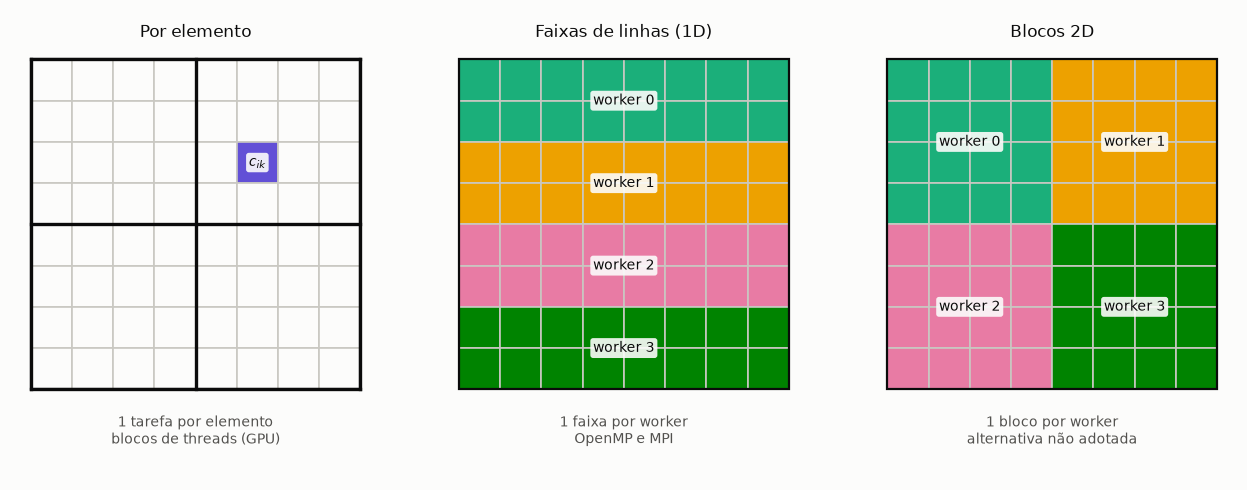

In [10]:
# Figura: três formas de decompor C entre os workers
N = 8
fig, axes = plt.subplots(1, 3, figsize=(13, 5), facecolor=SURF)

ax = axes[0]  # por elemento, agrupados em blocos de threads (GPU)
cc = draw_matrix(ax, 0, N, N, N, "Por elemento", {(2, 5): VIOLET})
for t in range(0, N + 1, 4):  # fronteiras dos blocos de threads
    ax.plot([t, t], [0, N], color=INK, lw=2.4); ax.plot([0, N], [t, t], color=INK, lw=2.4)
label(ax, cc(2, 5), r"$c_{ik}$", 10)
ax.text(N / 2, -0.6, "1 tarefa por elemento\nblocos de threads (GPU)", ha="center", va="top", fontsize=10, color=MUTED)
finish(ax, N, N, bottom=-2.2)

ax = axes[1]  # faixas de linhas 1D
fills = {(r, c): WORKER_COLORS[r // 2] for r in range(N) for c in range(N)}
cc = draw_matrix(ax, 0, N, N, N, "Faixas de linhas (1D)", fills)
for w in range(4):
    label(ax, (N / 2, N - 2 * w - 1), f"worker {w}")
ax.text(N / 2, -0.6, "1 faixa por worker\nOpenMP e MPI", ha="center", va="top", fontsize=10, color=MUTED)
finish(ax, N, N, bottom=-2.2)

ax = axes[2]  # blocos 2D
fills = {(r, c): WORKER_COLORS[2 * (r // 4) + c // 4] for r in range(N) for c in range(N)}
draw_matrix(ax, 0, N, N, N, "Blocos 2D", fills)
for w in range(4):
    label(ax, (2 + 4 * (w % 2), N - 2 - 4 * (w // 2)), f"worker {w}")
ax.text(N / 2, -0.6, "1 bloco por worker\nalternativa não adotada", ha="center", va="top", fontsize=10, color=MUTED)
finish(ax, N, N, bottom=-2.2)

fig.tight_layout()
save_figure(fig, "decomposition_options")

Nas versões OpenMP e MPI, dividimos $C$ em faixas de linhas. Cada faixa de $A$ e $C$ é contígua em memória. As faixas dão a cada *worker* uma região própria de escrita e preservam o laço interno da referência sequencial. Com `static`, uma faixa por thread já equilibra o número de linhas. Com `dynamic` e `guided`, o runtime pode entregar vários *chunks* à mesma thread.

A grade 2D de processos pode reduzir a replicação de dados em grande escala, mas exige trocar painéis entre grupos de processos. Escolhemos faixas 1D para trabalhar com poucos ranks e medir diretamente a comunicação de cada coletiva. Em CUDA, cada thread calcula um elemento de $C$ e cada bloco cobre um *tile*.

#### Balanceamento de carga

Cada elemento de $C$ acumula $m$ produtos. Se $n$ não é divisível por $P$, os primeiros $n \bmod P$ ranks recebem $\lfloor n/P\rfloor + 1$ linhas. Os demais recebem $\lfloor n/P\rfloor$. A diferença máxima é uma linha. Com $n = 4096$ e $P = 12$, são 342 ou 341 linhas, cerca de 0,3% de diferença. A figura ilustra a divisão de 10 linhas entre 4 *workers*.

Em um processador com núcleos de capacidades diferentes, a mesma quantidade de linhas pode levar tempos diferentes. Testamos `static`, `dynamic` e `guided` em OpenMP para medir se redistribuir *chunks* reduz a espera. Em MPI, a distribuição é fixa e a reunião de $C$ depende de todos os ranks.

Se $n < P$, alguns *workers* ficam sem trabalho. O programa MPI usa contagens zero para esses ranks e todos participam das coletivas. Na GPU, blocos que cruzam a borda carregam zeros nas posições fora das matrizes, e apenas threads com coordenadas válidas gravam em $C$.

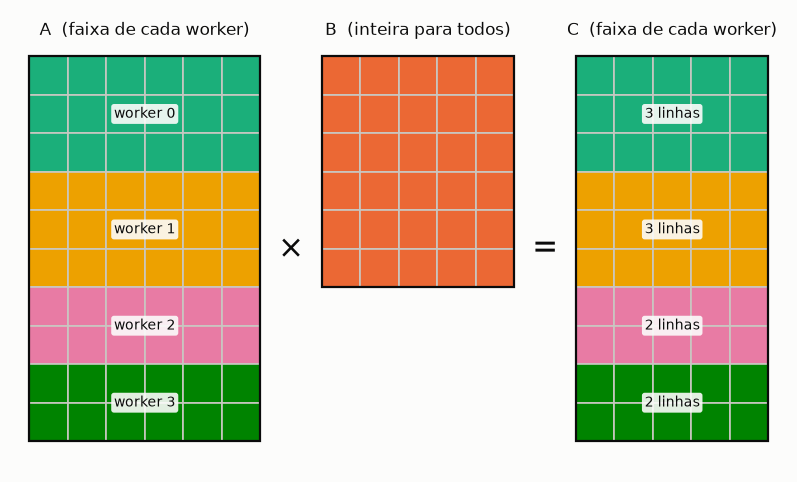

Divisão para n = 4096:
  P =  4: 1024 a 1024 linhas por worker (desbalanceamento de 0.00%)
  P = 12: 342 a 341 linhas por worker (desbalanceamento de 0.29%)
  P = 16: 256 a 256 linhas por worker (desbalanceamento de 0.00%)


In [11]:
def row_ranges(n, workers):
    """Divide n linhas entre workers: os primeiros n % workers recebem uma linha a mais."""
    base, extra = divmod(n, workers)
    ranges, start = [], 0
    for w in range(workers):
        size = base + (1 if w < extra else 0)
        ranges.append((start, start + size))
        start += size
    return ranges

# Figura: decomposição 1D por linhas com divisão não exata (n = 10, P = 4)
n, m, p, workers = 10, 6, 5, 4
ranges = row_ranges(n, workers)
owner = {r: w for w, (a, b) in enumerate(ranges) for r in range(a, b)}

fig, ax = plt.subplots(figsize=(12, 6), facecolor=SURF)
xa, xb, xc, top = product_layout(ax, n, m, p)
draw_matrix(ax, xa, top, n, m, "A  (faixa de cada worker)",
            {(r, c): WORKER_COLORS[owner[r]] for r in range(n) for c in range(m)})
draw_matrix(ax, xb, top, m, p, "B  (inteira para todos)", {(r, c): ORANGE for r in range(m) for c in range(p)})
draw_matrix(ax, xc, top, n, p, "C  (faixa de cada worker)",
            {(r, c): WORKER_COLORS[owner[r]] for r in range(n) for c in range(p)})
for w, (a, b) in enumerate(ranges):
    mid = top - (a + b) / 2
    label(ax, (xa + m / 2, mid), f"worker {w}")
    label(ax, (xc + p / 2, mid), f"{b - a} linhas")
finish(ax, xc + p, top, bottom=-0.8)
save_figure(fig, "row_decomposition")

print("Divisão para n = 4096:")
for P_ in [4, 12, 16]:
    sizes = [b - a for a, b in row_ranges(4096, P_)]
    print(f"  P = {P_:>2}: {max(sizes)} a {min(sizes)} linhas por worker "
          f"(desbalanceamento de {100 * (max(sizes) - min(sizes)) / max(sizes):.2f}%)")

#### Localidade e uso do cache

O laço interno percorre linhas de $B$ e $C$ de forma contígua. Uma linha de cache de 64 bytes pode conter 8 valores `double`. Cada linha $C[i]$ é reutilizada ao longo de $j$. Cada worker percorre $B$ repetidamente e o reaproveitamento depende de quanto da matriz cabe nos caches disponíveis. Por exemplo, $B$ ocupa 8 MiB com $n = 1024$ e 32 MiB com $n = 2048$.

A tabela calcula o tamanho de $B$ e a taxa sequencial em GFLOP/s. A relação depende da CPU, da banda de memória e dos demais dados em cache. Registre a configuração do equipamento junto aos resultados.

In [12]:
seq = results_table().query("impl == 'sequential'").copy()
seq["B_MiB"] = seq["m"] * seq["p"] * 8 / 2**20
seq["GFLOP_s"] = 2 * seq["n"] * seq["m"] * seq["p"] / seq["mean_s"] / 1e9
seq[["n", "mean_s", "B_MiB", "GFLOP_s"]].round(4)

,n,mean_s,B_MiB,GFLOP_s
0,256,0.0037,0.5,9.1343
1,512,0.0271,2.0,9.9005
2,1024,0.2829,8.0,7.5899
3,2048,4.4984,32.0,3.8191


OpenMP compartilha $B$ entre as threads, que também disputam banda de memória e os níveis de cache compartilhados. Com faixas contíguas, escritas numa mesma linha de cache podem se encontrar na fronteira entre duas faixas. Em MPI, cada rank tem a própria cópia de $B$, o que aumenta o uso de memória no nó.

Mantemos o laço `i-j-k` nas três versões de CPU para comparar a distribuição do mesmo trabalho. Em CUDA, cada bloco reutiliza os *tiles* de $A$ e $B$ em memória compartilhada, reduzindo carregamentos repetidos da memória global.

#### Comunicação

Em OpenMP, as threads leem as mesmas matrizes de entrada e escrevem em linhas distintas de $C$. O tráfego passa pela hierarquia de memória. A região paralela termina após a conclusão do trabalho de todas as threads.

Em MPI, o rank 0 distribui as faixas contíguas de $A$ com `MPI_Scatterv`, replica toda a matriz $B$ com `MPI_Bcast` e reúne as faixas de $C$ com `MPI_Gatherv`. Para linhas igualmente divididas, o volume lógico total, sem contar as fatias locais do rank 0, é

$$V_{1D} = 8\left[(1-1/P)(nm+np)+(P-1)mp\right]\;\mathrm{bytes}.$$

Esse é o volume de entregas entre ranks. O tráfego na rede depende da topologia, da distribuição dos ranks e da implementação das coletivas. Para comparação, numa grade $q\times q$ com $P=q^2$, blocos de $A$ e $B$ seriam distribuídos e, no modelo de comunicação por painéis, cada bloco seria entregue a $q-1$ outros ranks de sua linha ou coluna. A expressão da tabela inclui distribuição e reunião no rank 0 e supõe blocos iguais.

In [13]:
n = m = p = 4096
rows = []
for ranks in [4, 9, 16, 25]:
    q = ranks ** 0.5
    distribute_and_collect = (1 - 1 / ranks) * (n*m + n*p)
    one_d = distribute_and_collect + (ranks - 1) * m*p
    two_d = distribute_and_collect + (q - 1) * (n*m + m*p) + (1 - 1/ranks) * m*p
    rows.append(dict(ranks=ranks, MiB_1D=one_d * 8 / 2**20, MiB_2D=two_d * 8 / 2**20,
                     FLOP_por_byte_1D=2*n*m*p / (8*one_d)))
pd.DataFrame(rows).round(2)

,ranks,MiB_1D,MiB_2D,FLOP_por_byte_1D
0,4,576.00,544.00,227.56
1,9,1251.56,853.33,104.73
2,16,2160.00,1128.00,60.68
3,25,3317.76,1392.64,39.51


Ao aumentar o número de ranks com $n$, $m$ e $p$ fixos, cada rank calcula menos linhas, mas recebe os mesmos $mp$ valores de $B$. Em um nó, as mensagens podem usar memória compartilhada. Entre nós, o transporte usa a rede e adiciona custos de latência e banda. A comparação com o mesmo total de ranks em 1 e 2 nós mede o efeito da distribuição, que também muda o número de ranks disputando recursos em cada nó.

Em CUDA, $A$ e $B$ são transferidas para o dispositivo e $C$ retorna ao host. As transferências somam $8(nm + mp + np)$ bytes, ou 384 MiB para matrizes quadradas de ordem 4096. O programa registra as transferências e o tempo do kernel.

#### Granularidade

A granularidade é a quantidade de trabalho de cada tarefa em relação ao custo de criá-la, distribuí-la e sincronizá-la. Tarefas muito finas geram muito custo de gerenciamento, e tarefas muito grossas podem deixar *workers* ociosos se a carga não for bem dividida. Cada plataforma tem um ponto de equilíbrio diferente.

No OpenMP, a menor unidade que distribuímos é uma linha de $C$, com $2mp$ operações (33 milhões para $n = 4096$), muito acima do custo de escalonar uma tarefa, que é da ordem de microssegundos. Com o escalonamento `static`, cada thread recebe um único bloco de $n/P$ linhas, que é a granularidade mais grossa possível e tem custo de gerenciamento praticamente zero. Com o `dynamic`, as threads pegam blocos menores (*chunks*) conforme terminam, o que tem um custo maior, mas compensa a diferença de velocidade entre os núcleos. O tamanho do *chunk* é um parâmetro a ser ajustado experimentalmente.

No MPI, a granularidade é a mais grossa: uma única faixa por processo, porque cada envio de mensagem tem um custo fixo de latência e enviar muitas faixas pequenas seria ineficiente.

Na GPU, a granularidade é a mais fina: uma thread por elemento de $C$, ou seja, cerca de 16,8 milhões de threads para $n = 4096$. Isso só é viável porque as threads da GPU são extremamente leves e são escalonadas pelo hardware, e porque é preciso ter muito mais threads do que núcleos para esconder a latência da memória global. As threads são agrupadas em blocos (por exemplo, $16 \times 16 = 256$ threads), e o tamanho do bloco define tanto o reaproveitamento de dados no *tiling* quanto a ocupação dos multiprocessadores da GPU.

#### Resumo das decisões

| | OpenMP | MPI | GPU (CUDA) |
|---|---|---|---|
| Decomposição | faixas de linhas de $C$ | faixas de linhas de $C$ | um elemento de $C$ por thread, *tiles* 2D por bloco |
| Granularidade | um bloco por thread (`static`) ou *chunks* (`dynamic`) | uma faixa por processo | uma thread por elemento |
| Comunicação | nenhuma explícita, $B$ compartilhada | `Scatterv` de $A$, `Bcast` de $B$, `Gatherv` de $C$ | cópias *host* ↔ *device* |
| Balanceamento | divisão estática com resto distribuído; `dynamic` para núcleos heterogêneos | divisão estática com resto distribuído | blocos de borda parcialmente ociosos |
| Localidade | laço `i-j-k`, sem *tiling* | laço `i-j-k`, sem *tiling* | *tiling* com memória compartilhada |

### Implementação com memória compartilhada (OpenMP)

A versão OpenMP segue a decomposição 1D por faixas de linhas de $C$ definida na modelagem. O programa mantém o laço `i-j-k` da versão sequencial, com as iterações do laço externo `i` (as linhas de $C$) sendo divididas entre as threads. Isso é feito com três diretivas.

- `#pragma omp parallel` cria o time de threads;
- `#pragma omp single nowait` faz uma única thread registrar o tamanho do time, com `omp_get_num_threads()`, para que a linha `RESULT` informe quantas threads de fato executaram (o campo `workers`);
- `#pragma omp for schedule(runtime)` divide as iterações do laço `i` entre as threads.

As matrizes `A`, `B` e `C` e as dimensões são compartilhadas (`shared`). As variáveis do laço (`i`, `j`, `k` e `a_ij`) são privadas de cada thread, pois são declaradas dentro da região paralela. Vale destacar que o cálculo não precisa de sincronização, já que `A` e `B` só são lidas e cada linha de $C$ é escrita por uma única thread. Por isso o código não usa `atomic` nem `critical`, que serializariam as escritas e impediriam a vetorização do laço interno.

O número de threads e o escalonamento são escolhidos **na execução**, por variáveis de ambiente, e o programa é compilado uma única vez. `OMP_NUM_THREADS` define o número de threads e `OMP_SCHEDULE` define a política usada por `schedule(runtime)`, com o *chunk* opcional (`static`, `dynamic`, `guided` ou `dynamic,32`, por exemplo):

```
OMP_NUM_THREADS=8 OMP_SCHEDULE=dynamic,32 ./src/bin/openmp 2048
```

O nome da implementação na linha `RESULT` inclui a política (`openmp-static`, `openmp-dynamic-32`), o que permite distinguir as configurações na tabela `RESULTS`.

In [14]:
write_source('openmp.c', r"""#include "common.h"
#include <omp.h>

/* Escolhidos na EXECUÇÃO (o programa é compilado uma só vez):
 *   OMP_NUM_THREADS : número de threads do time
 *   OMP_SCHEDULE    : static | dynamic | guided, com chunk opcional (ex.: "dynamic,32") */

/* Multiplica A por B em paralelo e devolve quantas threads participaram. */
static int matmul_omp(dims_t d, const double *A, const double *B, double *C) {
    int n = d.n, m = d.m, p = d.p;
    int nthreads = 1;

    // Região paralela: cria o time de threads.
    // As matrizes e as dimensões são compartilhadas por todas as threads.
    #pragma omp parallel shared(A, B, C, n, m, p, nthreads)
    {
        // Só UMA thread do time registra o tamanho
        #pragma omp single nowait
        nthreads = omp_get_num_threads();

        // Worksharing: as iterações de i (linhas de C) são divididas entre as threads.
        // schedule(runtime): a política (static, dynamic...) é lida de OMP_SCHEDULE.
        // Variáveis declaradas dentro do laço (i, j, k, a_ij) são privadas de cada thread.
        #pragma omp for schedule(runtime)
        for (int i = 0; i < n; i++) {
            for (int j = 0; j < m; j++) {
                const double a_ij = A[(size_t)i * m + j];

                // Laço interno idêntico ao da versão sequencial: B[j][.] e C[i][.]
                for (int k = 0; k < p; k++)
                    C[(size_t)i * p + k] += a_ij * B[(size_t)j * p + k];
            }
        }
        // Ao sair da região paralela, C está completa.
    }

    return nthreads;
}

/* Nome da implementação na linha RESULT: "openmp-<política>", lido de OMP_SCHEDULE.
 * O chunk só aparece quando não é o padrão (ex.: "openmp-dynamic-32"). */
static void impl_name(char *buf, size_t size) {
    omp_sched_t kind;
    int chunk;
    omp_get_schedule(&kind, &chunk);        // política que schedule(runtime) vai usar

    // O bit mais alto é o modificador "monotonic" (OpenMP 5.0): removido para identificar a política.
    int base = (int)((unsigned)kind & 0x7fffffffu);

    if (base == omp_sched_static || base == omp_sched_dynamic || base == omp_sched_guided) {
        const char *name = (base == omp_sched_static)  ? "static"
                         : (base == omp_sched_dynamic) ? "dynamic" : "guided";
        int chunk_padrao = (base == omp_sched_static) ? 0 : 1;
        if (chunk > chunk_padrao) snprintf(buf, size, "openmp-%s-%d", name, chunk);
        else                      snprintf(buf, size, "openmp-%s", name);
    } else {
        snprintf(buf, size, "openmp-auto");
    }
}

int main(int argc, char **argv) {
    dims_t d = parse_dims(argc, argv);
    double *A = alloc_matrix(d.n, d.m, 0);
    double *B = alloc_matrix(d.m, d.p, 0);
    double *C = alloc_matrix(d.n, d.p, 1);
    init_matrices(d, A, B);

    // Tempo de parede só da multiplicação (a criação das threads entra, pois faz parte do custo).
    double t0 = wall_time();
    int nthreads = matmul_omp(d, A, B, C);
    double t1 = wall_time();

    char impl[64];
    impl_name(impl, sizeof impl);
    int valid = verify_matrix(d, A, B, C);
    if (valid) report(impl, d, nthreads, t1 - t0, checksum(d, C));
    free(A); free(B); free(C);
    return valid ? EXIT_SUCCESS : EXIT_FAILURE;
}
""")

Fonte preparada: openmp.c


A validação percorre os mesmos casos da versão sequencial. Para cada caso testamos as políticas `static`, `dynamic` e `guided`, incluindo *chunks* de 16 linhas, com as contagens de threads definidas na configuração. O produto escalar valida cada elemento e a soma é comparada com o NumPy e a versão sequencial.

In [15]:
compile_c("openmp.c", "openmp", flags="-O3 -fopenmp")

def omp_env(threads, schedule):
    """Número de threads e escalonamento são escolhidos por variáveis de ambiente."""
    return {"OMP_NUM_THREADS": str(threads), "OMP_SCHEDULE": schedule, "OMP_DYNAMIC": "FALSE"}

VALIDATION_SCHEDULES = ["static", "dynamic", "dynamic,16", "guided", "guided,16"]
VALIDATION_THREADS = THREADS

rows = []
for n, m, p in VALIDATION_CASES:
    ref = reference_checksum(n, m, p)                                    # NumPy
    seq = run_once(f"{BIN}/sequential {n} {m} {p}")["checksum"]      # versão sequencial
    results = []
    for schedule in VALIDATION_SCHEDULES:
        for threads in VALIDATION_THREADS:
            res = run_once(f"{BIN}/openmp {n} {m} {p}", env={**omp_env(threads, schedule), "MATMUL_VERIFY": "1"})
            assert res["workers"] == threads, res        # o time tem o tamanho pedido
            results.append(res)
    rows.append(dict(A=f"{n}×{m}", B=f"{m}×{p}", C=f"{n}×{p}", checksum_C=results[0]["checksum"],
                     checksum_numpy=ref, configuracoes=len(results),
                     correto=all(np.isclose(r["checksum"], ref, rtol=1e-9) for r in results),
                     igual_sequencial=all(np.isclose(r["checksum"], seq, rtol=1e-12) for r in results)))
validation_omp = pd.DataFrame(rows)
assert validation_omp[["correto", "igual_sequencial"]].all().all(), "A versão OpenMP divergiu do NumPy!"
validation_omp

gcc -O3 -fopenmp /tmp/matmul-54ruu9xj/src/openmp.c -o /tmp/matmul-54ruu9xj/bin/openmp


,A,B,C,checksum_C,checksum_numpy,configuracoes,correto,igual_sequencial
0,256×256,256×256,256×256,5033027.45,5033027.45,20,True,True
1,300×200,200×400,300×400,7199976.59,7199976.59,20,True,True
2,513×127,127×64,513×64,1250836.31,1250836.31,20,True,True
3,1×1000,1000×1,1×1,299.66,299.66,20,True,True
4,500×1,1×300,500×300,44867.94,44867.94,20,True,True
5,17×23,23×31,17×31,3631.00,3631.00,20,True,True
6,33×31,31×18,33×18,5511.00,5511.00,20,True,True


No ajuste, comparamos `static` com `dynamic` e `guided` usando *chunks* de 1, 8, 32 e 128 linhas. *Chunks* pequenos permitem redistribuição mais frequente, ao custo de mais acessos ao escalonador. Selecionamos o menor tempo médio de cada política dinâmica e medimos novamente as configurações selecionadas. Os tempos de seleção ficam fora da tabela principal.

In [16]:
TUNE_SIZE = min(1024, max(SIZES))
TUNE_SCHEDULES = ["static", "dynamic,1", "dynamic,8", "dynamic,32", "dynamic,128",
                  "guided,1", "guided,8", "guided,32", "guided,128"]

rows = []
for schedule in TUNE_SCHEDULES:
    res = benchmark(f"{BIN}/openmp {TUNE_SIZE}", env=omp_env(CPUS, schedule), phase="ajuste")
    rows.append(dict(escalonamento=schedule, tempo_medio_s=res["mean_s"], desvio_s=res["std_s"]))
tuning = pd.DataFrame(rows)

# Melhor chunk do dynamic consiste no de menor tempo médio entre as variantes dynamic
dynamic_rows = tuning[tuning["escalonamento"].str.startswith("dynamic")]
BEST_DYNAMIC = dynamic_rows.loc[dynamic_rows["tempo_medio_s"].idxmin(), "escalonamento"]

# O mesmo critério vale para o guided
guided_rows = tuning[tuning["escalonamento"].str.startswith("guided")]
BEST_GUIDED = guided_rows.loc[guided_rows["tempo_medio_s"].idxmin(), "escalonamento"]
print(f"\nMelhor chunk do dynamic: {BEST_DYNAMIC}")
print(f"Melhor chunk do guided: {BEST_GUIDED}\n")
tuning.round(4)

openmp-static       n=1024 workers=   8 | 0.041181 ± 0.002062 s


openmp-dynamic      n=1024 workers=   8 | 0.047842 ± 0.001529 s


openmp-dynamic-8    n=1024 workers=   8 | 0.041392 ± 0.001880 s


openmp-dynamic-32   n=1024 workers=   8 | 0.048153 ± 0.003793 s


openmp-dynamic-128  n=1024 workers=   8 | 0.044302 ± 0.002405 s


openmp-guided       n=1024 workers=   8 | 0.038450 ± 0.001684 s


openmp-guided-8     n=1024 workers=   8 | 0.040588 ± 0.001599 s


openmp-guided-32    n=1024 workers=   8 | 0.041043 ± 0.002632 s


openmp-guided-128   n=1024 workers=   8 | 0.043417 ± 0.002159 s

Melhor chunk do dynamic: dynamic,8
Melhor chunk do guided: guided,1



,escalonamento,tempo_medio_s,desvio_s
0,static,0.0412,0.0021
1,"dynamic,1",0.0478,0.0015
2,"dynamic,8",0.0414,0.0019
3,"dynamic,32",0.0482,0.0038
4,"dynamic,128",0.0443,0.0024
5,"guided,1",0.0385,0.0017
6,"guided,8",0.0406,0.0016
7,"guided,32",0.0410,0.0026
8,"guided,128",0.0434,0.0022


A comparação principal usa os mesmos tamanhos da versão sequencial. Medimos `static`, `dynamic` e `guided`, com os *chunks* selecionados no ajuste, variando a quantidade de threads até o limite definido na primeira célula.

In [17]:
FAMILIES = {"static": "static", "dynamic": BEST_DYNAMIC, "guided": BEST_GUIDED}   # política -> melhor chunk

SEQ_TIME = {}      # tempo sequencial de cada tamanho, medido junto das execuções OpenMP
rows = []
for n in SIZES:
    SEQ_TIME[n] = float(results_table().query("impl == 'sequential' and n == @n")["mean_s"].iloc[0])
    for schedule in FAMILIES.values():
        for threads in THREADS:
            res = benchmark(f"{BIN}/openmp {n} {n} {n}", env=omp_env(threads, schedule))
            rows.append(dict(escalonamento=schedule, n=n, threads=res["workers"],
                             tempo_s=res["mean_s"], desvio_s=res["std_s"]))
sweep = pd.DataFrame(rows)

openmp_results = results_table()
openmp_results[openmp_results["impl"].str.startswith("openmp")].round(4)

openmp-static       n= 256 workers=   1 | 0.003711 ± 0.000753 s
openmp-static       n= 256 workers=   2 | 0.002114 ± 0.000286 s
openmp-static       n= 256 workers=   4 | 0.001663 ± 0.000196 s
openmp-static       n= 256 workers=   8 | 0.001395 ± 0.000182 s
openmp-dynamic-8    n= 256 workers=   1 | 0.003299 ± 0.000165 s
openmp-dynamic-8    n= 256 workers=   2 | 0.002279 ± 0.000316 s
openmp-dynamic-8    n= 256 workers=   4 | 0.001279 ± 0.000051 s
openmp-dynamic-8    n= 256 workers=   8 | 0.001136 ± 0.000074 s
openmp-guided       n= 256 workers=   1 | 0.003187 ± 0.000072 s


openmp-guided       n= 256 workers=   2 | 0.002406 ± 0.000443 s
openmp-guided       n= 256 workers=   4 | 0.001496 ± 0.000050 s
openmp-guided       n= 256 workers=   8 | 0.001102 ± 0.000071 s


openmp-static       n= 512 workers=   1 | 0.026807 ± 0.001534 s


openmp-static       n= 512 workers=   2 | 0.017885 ± 0.003925 s
openmp-static       n= 512 workers=   4 | 0.008155 ± 0.000758 s


openmp-static       n= 512 workers=   8 | 0.006592 ± 0.000740 s


openmp-dynamic-8    n= 512 workers=   1 | 0.025324 ± 0.001161 s


... (23 outputs left out)

openmp-guided       n=2048 workers=   2 | 2.118840 ± 0.014918 s


openmp-guided       n=2048 workers=   4 | 1.102130 ± 0.009059 s


openmp-guided       n=2048 workers=   8 | 0.644549 ± 0.016228 s


,impl,n,m,p,workers,mean_s,std_s
0,openmp-dynamic-8,256,256,256,1,0.0033,0.0002
1,openmp-dynamic-8,256,256,256,2,0.0023,0.0003
2,openmp-dynamic-8,256,256,256,4,0.0013,0.0001
3,openmp-dynamic-8,256,256,256,8,0.0011,0.0001
4,openmp-dynamic-8,512,512,512,1,0.0253,0.0012
5,openmp-dynamic-8,512,512,512,2,0.0149,0.0012
6,openmp-dynamic-8,512,512,512,4,0.0081,0.0007
7,openmp-dynamic-8,512,512,512,8,0.0056,0.0008
8,openmp-dynamic-8,1024,1024,1024,1,0.3071,0.0249
9,openmp-dynamic-8,1024,1024,1024,2,0.1656,0.0217


O *speedup* de cada configuração é calculado em relação à versão sequencial, para o mesmo tamanho de matriz:

$$S = \frac{T_{\text{seq}}}{T_p},$$

em que $T_p$ é o tempo com $p$ threads e $T_{\text{seq}}$ é o tempo sequencial medido na seção sequencial. A tabela abaixo mostra o tempo médio e o *speedup* de cada resultado.

In [18]:
speedup_table = sweep.assign(tempo_seq_s=sweep["n"].map(SEQ_TIME))
speedup_table["speedup"] = speedup_table["tempo_seq_s"] / speedup_table["tempo_s"]
speedup_table = speedup_table[["escalonamento", "n", "threads", "tempo_seq_s", "tempo_s", "desvio_s", "speedup"]]
speedup_table.round({"tempo_seq_s": 4, "tempo_s": 4, "desvio_s": 4, "speedup": 2})

,escalonamento,n,threads,tempo_seq_s,tempo_s,desvio_s,speedup
0,static,256,1,0.0037,0.0037,0.0008,0.99
1,static,256,2,0.0037,0.0021,0.0003,1.74
2,static,256,4,0.0037,0.0017,0.0002,2.21
3,static,256,8,0.0037,0.0014,0.0002,2.63
4,"dynamic,8",256,1,0.0037,0.0033,0.0002,1.11
5,"dynamic,8",256,2,0.0037,0.0023,0.0003,1.61
6,"dynamic,8",256,4,0.0037,0.0013,0.0001,2.87
7,"dynamic,8",256,8,0.0037,0.0011,0.0001,3.23
8,"guided,1",256,1,0.0037,0.0032,0.0001,1.15
9,"guided,1",256,2,0.0037,0.0024,0.0004,1.53


O gráfico mostra o *speedup* em função do tamanho das matrizes, com todas as threads da máquina (`CPUS`). Cada curva é uma política de escalonamento no seu melhor *chunk*, escolhido no ajuste acima, e por isso o *chunk* pode ser diferente entre `dynamic` e `guided`. A linha tracejada marca o tempo da versão sequencial ($S = 1$) e a pontilhada, o *speedup* ideal ($S = p$).

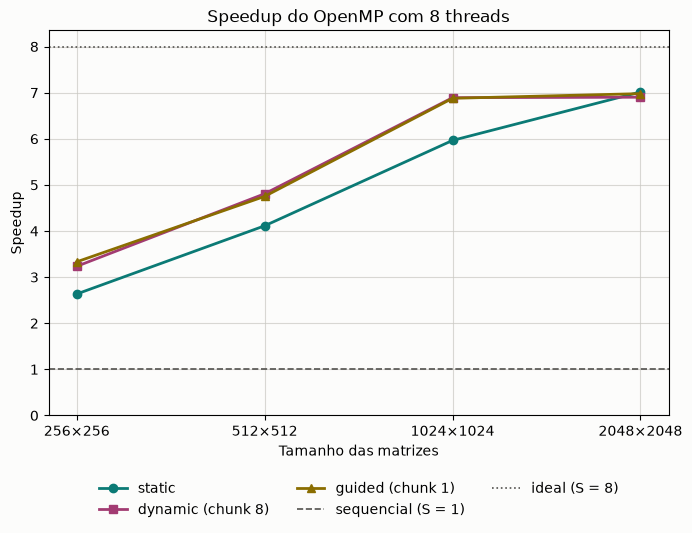

In [19]:
COLORS = {"static": "#0b7a75", "dynamic": "#a23b72", "guided": "#8a6d00"}
MARKERS = {"static": "o", "dynamic": "s", "guided": "^"}

fig, ax = plt.subplots(figsize=(8, 5), facecolor=SURF)
ax.set_facecolor(SURF)
positions = list(range(len(SIZES)))        # os tamanhos dobram a cada passo e as posições são igualmente espaçadas

for policy, schedule in FAMILIES.items():
    d = speedup_table[(speedup_table["escalonamento"] == schedule) & (speedup_table["threads"] == CPUS)]
    d = d.set_index("n").loc[SIZES]
    label = policy if policy == "static" else f"{policy} (chunk {schedule.split(',')[1]})"
    ax.plot(positions, d["speedup"], marker=MARKERS[policy], color=COLORS[policy], lw=2, label=label)

ax.axhline(1, color=MUTED, linestyle="--", lw=1.2, label="sequencial (S = 1)")
ax.axhline(CPUS, color=MUTED, linestyle=":", lw=1.2, label=f"ideal (S = {CPUS})")

ax.set_xticks(positions)
ax.set_xticklabels([f"{n}×{n}" for n in SIZES])
ax.set_xlabel("Tamanho das matrizes")
ax.set_ylabel("Speedup")
ax.set_ylim(bottom=0)
ax.set_title(f"Speedup do OpenMP com {CPUS} threads")
ax.grid(True, color=GRID, alpha=0.7)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)   # legenda abaixo, fora das curvas
save_figure(fig, "openmp_speedup")

### Implementação com memória distribuída (MPI)

Com $P$ ranks, o rank $r$ recebe $q+[r<s]$ linhas a partir de $rq+min(r,s)$, em que $q=\lfloor n/P\rfloor$ e $s=n\bmod P$. O rank 0 prepara as matrizes. O `Scatterv` usa contagens e deslocamentos em elementos de $A$, e o `Gatherv` usa os mesmos intervalos de linhas com a largura de $C$. Todos recebem $B$ por `Bcast` e calculam suas linhas com o laço `i-j-k`.

Cada rank mantém $mp$ valores de $B$ mais suas faixas de $A$ e $C$. O rank 0 mantém também as matrizes completas. Para $n=m=p=4096$, só a réplica de $B$ exige 128 MiB por rank. Os contadores MPI usados pelo código limitam cada matriz a `INT_MAX` elementos.

O rank 0 cronometra da primeira coletiva até o recebimento de $C$ completo. A linha `DETAIL` registra os nós usados, os tempos nas coletivas vistos pelo rank 0 e o maior tempo local no laço entre os ranks. O tempo registrado em `Gatherv` pode incluir espera por ranks mais lentos.

In [20]:
write_source('mpi.c', r"""#include "common.h"
#include <mpi.h>

int main(int argc, char **argv) {
    dims_t d = parse_dims(argc, argv);
    if (d.n > INT_MAX / d.m || d.m > INT_MAX / d.p || d.n > INT_MAX / d.p) {
        fprintf(stderr, "Matrizes excedem o limite de contagens int das coletivas MPI\n");
        return EXIT_FAILURE;
    }

    MPI_Init(&argc, &argv);
    int rank, ranks;
    MPI_Comm_rank(MPI_COMM_WORLD, &rank);
    MPI_Comm_size(MPI_COMM_WORLD, &ranks);

    int base = d.n / ranks, rest = d.n % ranks;
    int rows = base + (rank < rest);
    double *local_A = alloc_matrix(rows, d.m, 0);
    double *local_C = alloc_matrix(rows, d.p, 1);
    double *B = alloc_matrix(d.m, d.p, 0);
    double *A = NULL, *C = NULL;
    int *a_counts = NULL, *a_offsets = NULL, *c_counts = NULL, *c_offsets = NULL;
    if (rank == 0) {
        A = alloc_matrix(d.n, d.m, 0);
        C = alloc_matrix(d.n, d.p, 0);
        init_matrices(d, A, B);

        int *layout = malloc(4 * (size_t)ranks * sizeof(*layout));
        if (!layout) {
            fprintf(stderr, "Falha ao alocar a distribuição MPI\n");
            MPI_Abort(MPI_COMM_WORLD, EXIT_FAILURE);
        }
        a_counts = layout;
        a_offsets = a_counts + ranks;
        c_counts = a_offsets + ranks;
        c_offsets = c_counts + ranks;
        int first = 0;
        for (int r = 0; r < ranks; r++) {
            int count = base + (r < rest);
            a_counts[r] = count * d.m;
            a_offsets[r] = first * d.m;
            c_counts[r] = count * d.p;
            c_offsets[r] = first * d.p;
            first += count;
        }
    }

    MPI_Comm node;
    MPI_Comm_split_type(MPI_COMM_WORLD, MPI_COMM_TYPE_SHARED, rank, MPI_INFO_NULL, &node);
    int node_rank;
    MPI_Comm_rank(node, &node_rank);
    int leader = (node_rank == 0), nodes = 0;
    MPI_Reduce(&leader, &nodes, 1, MPI_INT, MPI_SUM, 0, MPI_COMM_WORLD);
    MPI_Comm_free(&node);

    MPI_Barrier(MPI_COMM_WORLD);
    double t0 = MPI_Wtime();
    MPI_Scatterv(A, a_counts, a_offsets, MPI_DOUBLE,
                 local_A, rows * d.m, MPI_DOUBLE, 0, MPI_COMM_WORLD);
    double t1 = MPI_Wtime();
    MPI_Bcast(B, d.m * d.p, MPI_DOUBLE, 0, MPI_COMM_WORLD);
    double t2 = MPI_Wtime();

    for (int i = 0; i < rows; i++)
        for (int j = 0; j < d.m; j++) {
            double a_ij = local_A[(size_t)i * d.m + j];
            for (int k = 0; k < d.p; k++)
                local_C[(size_t)i * d.p + k] += a_ij * B[(size_t)j * d.p + k];
        }

    double t3 = MPI_Wtime();
    MPI_Gatherv(local_C, rows * d.p, MPI_DOUBLE,
                C, c_counts, c_offsets, MPI_DOUBLE, 0, MPI_COMM_WORLD);
    double t4 = MPI_Wtime();

    double local_compute = t3 - t2, max_compute = 0.0;
    MPI_Reduce(&local_compute, &max_compute, 1, MPI_DOUBLE, MPI_MAX, 0, MPI_COMM_WORLD);
    int valid = 1;
    if (rank == 0) {
        valid = verify_matrix(d, A, B, C);
        if (valid) {
            report("mpi", d, ranks, t4 - t0, checksum(d, C));
            printf("DETAIL,mpi,%d,%.9f,%.9f,%.9f,%.9f\n",
                   nodes, t1 - t0, t2 - t1, max_compute, t4 - t3);
        }
    }
    free(a_counts);
    free(A);
    free(B);
    free(C);
    free(local_A);
    free(local_C);
    MPI_Finalize();
    return valid ? EXIT_SUCCESS : EXIT_FAILURE;
}
""")

Fonte preparada: mpi.c


In [21]:
compile_c("mpi.c", "mpi", compiler="mpicc")
print(subprocess.check_output(["mpicc", "-show"], text=True).strip())
MPI_CMD = "mpirun --oversubscribe --bind-to none"
MPI_ENV = {"OMPI_ALLOW_RUN_AS_ROOT": "1", "OMPI_ALLOW_RUN_AS_ROOT_CONFIRM": "1"}

rows = []
for n, m, p in [*VALIDATION_CASES, (2, 19, 17)]:
    ref = reference_checksum(n, m, p)
    for ranks in (1, 3, 4):
        res = run_once(f"{MPI_CMD} -np {ranks} {BIN}/mpi {n} {m} {p}",
                       env={**MPI_ENV, "MATMUL_VERIFY": "1"})
        assert res["workers"] == ranks and res["nodes"] == 1, res
        assert np.isclose(res["checksum"], ref, rtol=1e-9, atol=1e-12), res
        rows.append(dict(n=n, m=m, p=p, ranks=ranks, checksum=res["checksum"]))
pd.DataFrame(rows)

mpicc -O3 /tmp/matmul-54ruu9xj/src/mpi.c -o /tmp/matmul-54ruu9xj/bin/mpi
gcc -I/usr/lib/x86_64-linux-gnu/openmpi/include -I/usr/lib/x86_64-linux-gnu/openmpi/include/openmpi -L/usr/lib/x86_64-linux-gnu/openmpi/lib -lmpi


,n,m,p,ranks,checksum
0,256,256,256,1,5033027.45
1,256,256,256,3,5033027.45
2,256,256,256,4,5033027.45
3,300,200,400,1,7199976.59
4,300,200,400,3,7199976.59
5,300,200,400,4,7199976.59
6,513,127,64,1,1250836.31
7,513,127,64,3,1250836.31
8,513,127,64,4,1250836.31
9,1,1000,1,1,299.66


#### Execução local e no OpenHPC da UFSCar

A célula seguinte mede MPI no ambiente do notebook. No cluster, carregue o ambiente MPI da disciplina, entre na raiz do repositório e envie os jobs. O exemplo usa PMIx. Ajuste o tipo MPI, a conta e a partição conforme a configuração do OpenHPC.

```bash
MPI_TYPE=pmix sbatch --nodes=1 --ntasks=8 --ntasks-per-node=8 scripts/openhpc.sbatch
MPI_TYPE=pmix sbatch --nodes=2 --ntasks=8 --ntasks-per-node=4 scripts/openhpc.sbatch
```

Cada job valida um caso retangular, mede a referência sequencial na própria alocação e registra o número de nós efetivamente usados pelo MPI.

Copie os arquivos `matmul-openhpc-*.log` para o diretório atual do notebook (no Colab, faça upload pela aba **Arquivos**). A análise importa os logs automaticamente e calcula o *speedup* de cada job usando sua própria referência.

In [22]:
for n in SIZES:
    for ranks in THREADS:
        benchmark(f"{MPI_CMD} -np {ranks} {BIN}/mpi {n}", env=MPI_ENV)

mpi                 n= 256 workers=   1 | 0.003948 ± 0.000756 s


mpi                 n= 256 workers=   2 | 0.002251 ± 0.000224 s


mpi                 n= 256 workers=   4 | 0.001507 ± 0.000383 s


mpi                 n= 256 workers=   8 | 0.002518 ± 0.000671 s


mpi                 n= 512 workers=   1 | 0.028270 ± 0.003285 s


mpi                 n= 512 workers=   2 | 0.015842 ± 0.001469 s


... (6 outputs left out)

mpi                 n=2048 workers=   1 | 4.043685 ± 0.034514 s


mpi                 n=2048 workers=   2 | 2.207310 ± 0.008546 s


mpi                 n=2048 workers=   4 | 1.404451 ± 0.030975 s


mpi                 n=2048 workers=   8 | 1.073670 ± 0.022295 s


### Implementação em GPU com CUDA

Cada bloco de $16\times16$ threads cobre um *tile* do resultado. A thread `(x, y)` calcula $C[i,k]$, com $i=16\cdot\text{blockIdx.y}+y$ e $k=16\cdot\text{blockIdx.x}+x$. A grade usa arredondamento para cima nas duas dimensões de $C$.

1. Para cada faixa de 16 valores de $j$, as threads carregam um *tile* de $A$ e outro de $B$ da memória global para a compartilhada. Posições de borda fora da matriz recebem zeros.
2. Uma barreira espera o carregamento. Cada thread acumula 16 produtos usando a linha de $A$ e a coluna de $B$ do *tile*. Outra barreira protege os dados até que todas as threads terminem de lê-los.
3. Ao final, cada thread dentro de $C$ grava o próprio resultado. Threads de borda participam das barreiras e só descartam a escrita final quando a coordenada está fora de $C$.

Cada bloco usa $2\cdot16^2\cdot8=4096$ bytes de memória compartilhada para os dois *tiles*. O código usa FP64 como as versões de CPU. Em GPUs GeForce RTX 4050/4060, a taxa de FP64 é menor que a de FP32, por isso o resultado deve ser interpretado como a aceleração deste algoritmo em FP64. O tempo principal inclui as duas entradas e a saída pelo barramento, e eventos CUDA medem o kernel. Em dimensões que não são múltiplas de 16, a taxa em GFLOP/s usa o trabalho útil $2nmp$.

In [23]:
write_source('cuda.cu', r"""#include "common.h"
#include <cuda_runtime.h>

constexpr int TILE = 16;

static void check_cuda(cudaError_t status, const char *operation) {
    if (status != cudaSuccess) {
        fprintf(stderr, "%s: %s\n", operation, cudaGetErrorString(status));
        exit(EXIT_FAILURE);
    }
}

#define CUDA(call) check_cuda((call), #call)

__global__ void matmul_cuda(dims_t d, const double *A, const double *B, double *C) {
    __shared__ double tile_A[TILE][TILE];
    __shared__ double tile_B[TILE][TILE];
    const int x = threadIdx.x, y = threadIdx.y;
    const int i = blockIdx.y * TILE + y, k = blockIdx.x * TILE + x;
    double sum = 0.0;

    for (int tile = 0; tile <= (d.m - 1) / TILE; tile++) {
        int a_col = tile * TILE + x, b_row = tile * TILE + y;
        tile_A[y][x] = (i < d.n && a_col < d.m) ? A[(size_t)i * d.m + a_col] : 0.0;
        tile_B[y][x] = (b_row < d.m && k < d.p) ? B[(size_t)b_row * d.p + k] : 0.0;
        __syncthreads();

        for (int j = 0; j < TILE; j++)
            sum += tile_A[y][j] * tile_B[j][x];
        // Todas as threads devem terminar a leitura antes de carregar o próximo tile.
        __syncthreads();
    }
    if (i < d.n && k < d.p) C[(size_t)i * d.p + k] = sum;
}

int main(int argc, char **argv) {
    dims_t d = parse_dims(argc, argv);
    const dim3 block(TILE, TILE);
    const dim3 grid(1 + (d.p - 1) / TILE, 1 + (d.n - 1) / TILE);
    int device;
    cudaDeviceProp props;
    CUDA(cudaGetDevice(&device));
    CUDA(cudaGetDeviceProperties(&props, device));
    if (grid.x > (unsigned)props.maxGridSize[0] || grid.y > (unsigned)props.maxGridSize[1] ||
        (size_t)grid.x * grid.y > INT_MAX) {
        fprintf(stderr, "Dimensões excedem a capacidade da grade CUDA\n");
        return EXIT_FAILURE;
    }

    double *A = alloc_matrix(d.n, d.m, 0);
    double *B = alloc_matrix(d.m, d.p, 0);
    double *C = alloc_matrix(d.n, d.p, 0);
    init_matrices(d, A, B);
    size_t a_bytes = (size_t)d.n * d.m * sizeof(double);
    size_t b_bytes = (size_t)d.m * d.p * sizeof(double);
    size_t c_bytes = (size_t)d.n * d.p * sizeof(double);
    double *device_A, *device_B, *device_C;
    CUDA(cudaMalloc(&device_A, a_bytes));
    CUDA(cudaMalloc(&device_B, b_bytes));
    CUDA(cudaMalloc(&device_C, c_bytes));
    cudaEvent_t start, stop;
    CUDA(cudaEventCreate(&start));
    CUDA(cudaEventCreate(&stop));
    cudaFuncAttributes attributes;
    CUDA(cudaFuncGetAttributes(&attributes, matmul_cuda));

    double t0 = wall_time();
    CUDA(cudaMemcpy(device_A, A, a_bytes, cudaMemcpyHostToDevice));
    CUDA(cudaMemcpy(device_B, B, b_bytes, cudaMemcpyHostToDevice));
    CUDA(cudaDeviceSynchronize());
    double t1 = wall_time();
    CUDA(cudaEventRecord(start));
    matmul_cuda<<<grid, block>>>(d, device_A, device_B, device_C);
    CUDA(cudaGetLastError());
    CUDA(cudaEventRecord(stop));
    CUDA(cudaEventSynchronize(stop));
    double t2 = wall_time();
    CUDA(cudaMemcpy(C, device_C, c_bytes, cudaMemcpyDeviceToHost));
    double t3 = wall_time();

    float kernel_ms = 0.0f;
    CUDA(cudaEventElapsedTime(&kernel_ms, start, stop));
    int valid = verify_matrix(d, A, B, C);
    if (valid) {
        report("cuda", d, (int)(grid.x * grid.y), t3 - t0, checksum(d, C));
        printf("DETAIL,cuda,%.9f,%.9f,%.9f\n", t1 - t0, kernel_ms * 1e-3, t3 - t2);
    }
    CUDA(cudaEventDestroy(start));
    CUDA(cudaEventDestroy(stop));
    CUDA(cudaFree(device_A));
    CUDA(cudaFree(device_B));
    CUDA(cudaFree(device_C));
    free(A);
    free(B);
    free(C);
    return valid ? EXIT_SUCCESS : EXIT_FAILURE;
}
""")

Fonte preparada: cuda.cu


In [24]:
GPU_READY = False
if shutil.which("nvidia-smi") and shutil.which("nvcc"):
    found = subprocess.run(["nvidia-smi", "--query-gpu=name,driver_version", "--format=csv,noheader"],
                           capture_output=True, text=True)
    GPU_READY = found.returncode == 0 and bool(found.stdout.strip())
    if GPU_READY:
        GPU_INFO = found.stdout.strip()
        print(GPU_INFO)
        print(subprocess.check_output(["nvcc", "--version"], text=True).strip())
        compile_c("cuda.cu", "cuda", compiler="nvcc", flags="-O3 -arch=native")

if GPU_READY:
    rows = []
    for n, m, p in VALIDATION_CASES:
        res = run_once(f"{BIN}/cuda {n} {m} {p}", env={"MATMUL_VERIFY": "1"})
        assert res["workers"] == ((n + 15)//16)*((p + 15)//16), res
        assert np.isclose(res["checksum"], reference_checksum(n, m, p), rtol=1e-9, atol=1e-12), res
        rows.append(dict(n=n, m=m, p=p, blocos=res["workers"], checksum=res["checksum"]))
    display(pd.DataFrame(rows))
    for n in SIZES:
        benchmark(f"{BIN}/cuda {n}")
else:
    print("Medições CUDA pendentes. Use uma GPU NVIDIA com nvcc ou o ambiente GPU do Colab.")

Medições CUDA pendentes. Use uma GPU NVIDIA com nvcc ou o ambiente GPU do Colab.


### Análise de desempenho

Usamos a média e o desvio padrão amostral de cinco execuções por configuração, mantendo fixo o tamanho das matrizes em cada comparação de escalabilidade forte. O *speedup* é $S=T_{seq}/T_{par}$ e a eficiência CPU é $S/P$ para $P$ threads ou ranks. A taxa é $2nmp / T_{par}$ em GFLOP/s. A referência sequencial de cada ambiente ou job é medida na mesma execução do estudo. O ajuste de escalonamento OpenMP fica fora da amostra principal.

A fração de tempo do rank 0 nas coletivas indica quanto do tempo ele permanece nessas chamadas, incluindo esperas. O máximo dos tempos de computação dos ranks tem um relógio lógico diferente dessas fases e pode se sobrepor à espera em `Gatherv`. Para CUDA, a análise mostra a fração de tempo das cópias e a taxa do kernel, além da taxa de ponta a ponta.

In [25]:
def load_openhpc(path):
    lines = path.read_text(encoding="utf-8").splitlines()
    header = next(line for line in lines if line.startswith("RUN,openhpc,"))
    _, _, job, expected_nodes, expected_reps = header.split(",")
    assert f"DONE,openhpc,{job}" in lines, f"Job ainda não concluído em {path.name}"
    counters, runs = {}, []
    for i, line in enumerate(lines):
        if not line.startswith("RESULT,"):
            continue
        following = lines[i + 1] if i + 1 < len(lines) else ""
        res = parse_output(line + "\n" + following if following.startswith("DETAIL,") else line)
        if res["impl"] == "mpi":
            assert res["nodes"] == int(expected_nodes), (path, res)
        key = (res["impl"], res["n"], res["m"], res["p"], res["workers"])
        counters[key] = counters.get(key, 0) + 1
        runs.append({**res, "run": f"OpenHPC {job}", "phase": "principal", "rep": counters[key]})
    assert counters and set(counters.values()) == {int(expected_reps)}, f"Job incompleto em {path.name}"
    assert {r["impl"] for r in runs} == {"sequential", "mpi"}, path.name
    return runs


local = pd.DataFrame(RESULTS).assign(data_utc=RUN_DATE, cpu=CPU_MODEL, gpu=GPU_INFO)
local.to_csv(RUN_DIR / "matmul-local.csv", index=False)
logs = sorted(RUN_DIR.glob("matmul-openhpc-*.log"))
cluster = [res for path in logs for res in load_openhpc(path)]
if not cluster:
    print("Aguardando logs do OpenHPC. As medições MPI desta execução são locais.")

runs = pd.DataFrame([*RESULTS, *cluster]).query("phase == 'principal'").copy()
keys = ["run", "n", "m", "p"]
reference = runs.query("impl == 'sequential'").groupby(keys)["checksum"].first().rename("ref")
checked = runs.join(reference, on=keys)
assert np.isclose(checked["checksum"], checked["ref"], rtol=1e-9, atol=1e-12).all()
print(f"{len(runs)} medições principais com checksum validado.")
runs["collectives_s"] = runs[["scatter_s", "bcast_s", "gather_s"]].sum(axis=1, min_count=3)
for col in ("h2d_s", "kernel_s", "d2h_s"):
    if col not in runs:
        runs[col] = np.nan
runs["copies_s"] = runs["h2d_s"] + runs["d2h_s"]

summary = (runs.groupby([*keys, "impl", "nodes", "workers"])
           .agg(reps=("time_s", "size"), mean_s=("time_s", "mean"), std_s=("time_s", "std"),
                collectives_s=("collectives_s", "mean"), max_compute_s=("compute_max_s", "mean"),
                scatter_s=("scatter_s", "mean"), bcast_s=("bcast_s", "mean"),
                gather_s=("gather_s", "mean"), copies_s=("copies_s", "mean"), kernel_s=("kernel_s", "mean"))
           .reset_index())
seq_time = summary.query("impl == 'sequential'").set_index(keys)["mean_s"].rename("seq_s")
summary = summary.join(seq_time, on=keys)
summary["speedup"] = summary["seq_s"] / summary["mean_s"]
summary["efficiency"] = (summary["speedup"] / summary["workers"]).where(summary["impl"] != "cuda")
summary["GFLOP_s"] = 2 * summary["n"] * summary["m"] * summary["p"] / (summary["mean_s"] * 1e9)
summary["GFLOP_s_kernel"] = summary["GFLOP_s"] * summary["mean_s"] / summary["kernel_s"]
summary["coletivas_%"] = 100 * summary["collectives_s"] / summary["mean_s"]
summary["copias_%"] = 100 * summary["copies_s"] / summary["mean_s"]
with pd.option_context("display.max_rows", 120):
    display(summary[["run", "impl", "n", "nodes", "workers", "reps", "mean_s", "std_s",
                     "speedup", "efficiency", "GFLOP_s"]].round(4))

Aguardando logs do OpenHPC. As medições MPI desta execução são locais.
340 medições principais com checksum validado.


,run,impl,n,nodes,workers,reps,mean_s,std_s,speedup,efficiency,GFLOP_s
0,local,mpi,256,1,1,5,0.0039,0.0008,0.9304,0.9304,8.4985
1,local,mpi,256,1,2,5,0.0023,0.0002,1.6319,0.8160,14.9062
2,local,mpi,256,1,4,5,0.0015,0.0004,2.4380,0.6095,22.2692
3,local,mpi,256,1,8,5,0.0025,0.0007,1.4591,0.1824,13.3282
4,local,openmp-dynamic-8,256,1,1,5,0.0033,0.0002,1.1137,1.1137,10.1726
5,local,openmp-dynamic-8,256,1,2,5,0.0023,0.0003,1.6121,0.8061,14.7254
6,local,openmp-dynamic-8,256,1,4,5,0.0013,0.0001,2.8714,0.7178,26.2277
7,local,openmp-dynamic-8,256,1,8,5,0.0011,0.0001,3.2344,0.4043,29.5440
8,local,openmp-guided,256,1,1,5,0.0032,0.0001,1.1526,1.1526,10.5286
9,local,openmp-guided,256,1,2,5,0.0024,0.0004,1.5271,0.7635,13.9486


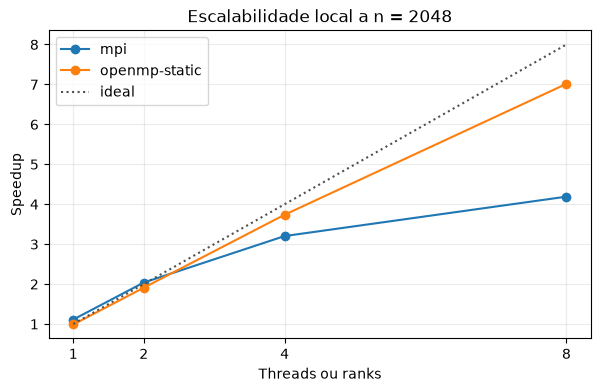

,run,n,nodes,workers,mean_s,scatter_s,bcast_s,max_compute_s,gather_s,coletivas_%
0,local,256,1,1,0.00395,0.00014,0.00000,0.00363,0.00018,8.05948
1,local,256,1,2,0.00225,0.00019,0.00013,0.00180,0.00024,24.68323
2,local,256,1,4,0.00151,0.00024,0.00031,0.00084,0.00026,53.67273
3,local,256,1,8,0.00252,0.00050,0.00094,0.00061,0.00064,82.50080
17,local,512,1,1,0.02827,0.00062,0.00000,0.02688,0.00077,4.91645
18,local,512,1,2,0.01584,0.00076,0.00062,0.01391,0.00138,17.39966
19,local,512,1,4,0.01149,0.00072,0.00055,0.00865,0.00349,41.51044
20,local,512,1,8,0.00955,0.00105,0.00247,0.00573,0.00198,57.55574
34,local,1024,1,1,0.24269,0.00265,0.00000,0.23710,0.00293,2.30065
35,local,1024,1,2,0.17652,0.00274,0.00299,0.16803,0.00838,7.99732


In [26]:
local_summary = summary.query("run == @LOCAL_RUN")
largest = max(SIZES)
cpu = local_summary.query("n == @largest and impl in ['openmp-static', 'mpi']")
fig, ax = plt.subplots(figsize=(7, 4))
for impl, data in cpu.groupby("impl"):
    ax.plot(data["workers"], data["speedup"], marker="o", label=impl)
ax.plot(THREADS, THREADS, linestyle=":", color=MUTED, label="ideal")
ax.set(xlabel="Threads ou ranks", ylabel="Speedup", title=f"Escalabilidade local a n = {largest}")
ax.set_xticks(THREADS)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

mpi_cols = ["run", "n", "nodes", "workers", "mean_s", "scatter_s", "bcast_s",
            "max_compute_s", "gather_s", "coletivas_%"]
display(summary.query("impl == 'mpi'")[mpi_cols].round(5))
gpu = local_summary.query("impl == 'cuda'")
if not gpu.empty:
    display(gpu[["n", "workers", "mean_s", "kernel_s", "copies_s", "copias_%",
                 "GFLOP_s_kernel", "speedup"]].round(5))

if cluster:
    cluster_mpi = summary.query("run != @LOCAL_RUN and impl == 'mpi'")
    # Mesmo tamanho e total de ranks, com um resumo por job e quantidade de nós.
    compare = cluster_mpi.groupby(["n", "workers"])["nodes"].transform("nunique") > 1
    display(cluster_mpi.loc[compare, ["run", "n", "workers", "nodes", "mean_s",
                                     "std_s", "coletivas_%", "speedup"]].round(5))

### Interpretação dos resultados

O trabalho por rank cai com $P$, mas a réplica de $B$ permanece inteira em cada processo. A leitura do tempo de coletivas leva em conta o maior tempo de computação e o tamanho de $B$. Em OpenMP, diferenças de médias próximas dos desvios padrão pedem novas repetições antes de atribuir um ganho ao tamanho do *chunk* ou à redistribuição.

No OpenHPC, a comparação com o mesmo tamanho e total de ranks em um e dois nós combina o custo da comunicação entre nós com a redução do número de ranks disputando os recursos de cada nó. Em CUDA, a fração de cópias mostra quanto da execução foi gasto transportando os dados. A taxa do kernel e a taxa total quantificam o efeito sobre o desempenho.

In [27]:
top_omp = local_summary[local_summary["impl"].str.startswith("openmp") & local_summary["n"].eq(largest)]
top_omp = top_omp.loc[top_omp["mean_s"].idxmin()]
local_mpi = local_summary.query("impl == 'mpi' and workers == @CPUS").set_index("n")
small, big = local_mpi.loc[min(SIZES)], local_mpi.loc[largest]
explanation = [
    f"Em **{CPU_MODEL}**, com n = {largest}, o menor tempo médio OpenMP foi "
    f"**{top_omp.mean_s:.4f} s** ({top_omp.impl}, {top_omp.workers} threads), "
    f"com speedup de **{top_omp.speedup:.2f}×**.",
    f"Com {CPUS} ranks em um nó, o MPI obteve **{big.speedup:.2f}×** de speedup "
    f"em n = {largest}. O rank 0 passou **{small['coletivas_%']:.1f}%** do tempo nas "
    f"coletivas em n = {min(SIZES)} e **{big['coletivas_%']:.1f}%** em n = {largest}. "
    "Essa fração inclui espera pelo restante do trabalho.",
]
if not gpu.empty:
    measured = gpu.loc[gpu["n"].idxmax()]
    explanation.append(f"Em CUDA, para n = {measured.n}, o speedup total foi "
                       f"**{measured.speedup:.2f}×** e as cópias ocuparam "
                       f"**{measured['copias_%']:.1f}%** do tempo total.")
if not cluster:
    explanation.append("O experimento entre nós aguarda os logs do OpenHPC.")
display(Markdown("\n\n".join(explanation)))

Em **Intel(R) Core(TM) i5-14600K**, com n = 2048, o menor tempo médio OpenMP foi **0.6413 s** (openmp-static, 8 threads), com speedup de **7.01×**.

Com 8 ranks em um nó, o MPI obteve **4.19×** de speedup em n = 2048. O rank 0 passou **82.5%** do tempo nas coletivas em n = 256 e **5.6%** em n = 2048. Essa fração inclui espera pelo restante do trabalho.

O experimento entre nós aguarda os logs do OpenHPC.